<a href="https://colab.research.google.com/github/Patiencepaco/Housing-price-prediction-/blob/patience-branch/Patience_Housing_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STEP 1: DATA SETUP AND LOADING

In [3]:

# Housing Price Prediction Project
# Author: Patience Paco Mulbah

#importing tools and laoding data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

#load file from uploaded data in colab
train = pd.read_csv("train.csv", index_col=0)
test = pd.read_csv("test.csv", index_col=0)

print("Data loaded successfully!")
print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

# preview of the data
train.head()

Data loaded successfully!
Training data shape: (355, 14)
Testing data shape: (151, 13)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
374,11.10810,0.0,18.10,0,0.668,4.906,100.0,1.1742,24,666,20.2,396.90,34.77,13.8
210,0.43571,0.0,10.59,1,0.489,5.344,100.0,3.8750,4,277,18.6,396.90,23.09,20.0
117,0.13158,0.0,10.01,0,0.547,6.176,72.5,2.7301,6,432,17.8,393.30,12.04,21.2
444,9.96654,0.0,18.10,0,0.740,6.485,100.0,1.9784,24,666,20.2,386.73,18.85,15.4
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


STEP 2: DATA EXPLORATION (EDA)

Total missing values in training data: 0

Top 5 features most correlated with price:
MEDV    1.000000
RM      0.666058
ZN      0.395225
B       0.357081
DIS     0.237746
CHAS    0.144943
Name: MEDV, dtype: float64


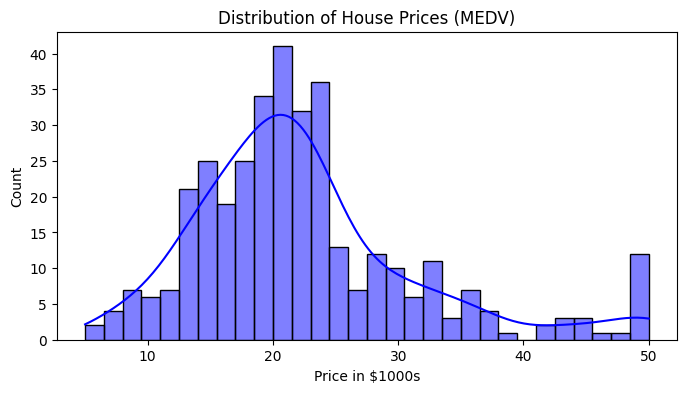

In [4]:
# Before building models, let's see what affects the house prices the most.

# Checking for missing values
print("Total missing values in training data:", train.isnull().sum().sum())

# Let's look at the correlation with the target median value(MEDV)
correlations = train.corr()['MEDV'].sort_values(ascending=False)
print("\nTop 5 features most correlated with price:")
print(correlations.head(6))

# Visualize the price distribution
plt.figure(figsize=(8, 4))
sns.histplot(train['MEDV'], kde=True, bins=30, color='blue')
plt.title("Distribution of House Prices (MEDV)")
plt.xlabel("Price in $1000s")
plt.show()